# Weak Supervision for SMS Spam, Part 3: Data Slicing

A good overall score can hide groups of messages where a model does badly. Snorkel's **slicing functions (SFs)** mark those groups so I can track them separately, and its `SliceAwareClassifier` can give a model extra capacity for them.

Like the original slicing tutorial, this notebook uses the real train labels, since slicing normally comes after the training set is labeled.

Plan:
1. Write SFs for SMS
2. Score a plain model per slice with Snorkel's `Scorer`
3. Train a slice-aware model and compare it slice by slice

In [1]:
import logging
import os
import random
import warnings

os.environ["PYTHONHASHSEED"] = "0"
os.environ["TQDM_DISABLE"] = "1"

import numpy as np
import pandas as pd
import torch
from sklearn.exceptions import UndefinedMetricWarning

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

logging.getLogger().setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
# numpy on macOS prints harmless matmul warnings during scikit-learn predictions
warnings.filterwarnings("ignore", message=".*encountered in matmul")
# F1 is undefined on a slice with no spam; that case is explained below
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
pd.set_option("display.max_colwidth", 100)

In [2]:
from utils import load_spam_dataset

df_train, df_test = load_spam_dataset(load_train_labels=True)
print(f"train: {len(df_train)}, test: {len(df_test)}")

train: 3619, test: 1035


## 1. Slicing functions

An SF looks like an LF, but it returns True or False: is this message in the slice? Four slices I care about for SMS:

- `short_message`: fewer than 5 words. Tiny texts give a model very little to work with.
- `has_url`: contains a link. Links are where phishing lives, so missing spam here is costly.
- `has_currency_or_number`: contains a currency symbol or any digit. Both ham ("see you at 7") and spam ("call 0906...") use numbers, so this is where the classes look most alike.
- `mostly_uppercase`: more than half the letters are uppercase. Part 1 showed these are mostly friends texting in caps, so a model that treats caps as spammy would slip up here.

`has_url` and `has_currency_or_number` share one regex template built with `SlicingFunction` and `resources`, the same pattern as the keyword LFs in part 1.

In [3]:
import re

from snorkel.slicing import SlicingFunction, slicing_function


@slicing_function()
def short_message(x):
    return len(x.text.split()) < 5


def regex_lookup(x, pattern):
    return bool(re.search(pattern, x.text, flags=re.I))


def make_regex_sf(name, pattern):
    return SlicingFunction(name=name, f=regex_lookup, resources=dict(pattern=pattern))


has_url = make_regex_sf("has_url", r"https?://|www\.|\b\w+\.(?:com|net|org|co\.uk|biz|info)\b")
has_currency_or_number = make_regex_sf("has_currency_or_number", r"[£$€]|\d")


@slicing_function()
def mostly_uppercase(x):
    letters = [c for c in x.text if c.isalpha()]
    return len(letters) >= 10 and sum(c.isupper() for c in letters) / len(letters) > 0.5


sfs = [short_message, has_url, has_currency_or_number, mostly_uppercase]

`slice_dataframe` returns the messages in one slice. Here are a few from `mostly_uppercase` in test.

In [4]:
from snorkel.slicing import slice_dataframe

slice_dataframe(df_test, mostly_uppercase)[["text", "label"]].head(6)

,text,label
23,MAYBE IF YOU WOKE UP BEFORE FUCKING 3 THIS WOULDN'T BE A PROBLEM.,0
35,THANX 4 PUTTIN DA FONE DOWN ON ME!!,0
102,I REALLY NEED 2 KISS U I MISS U MY BABY FROM UR BABY 4EVA,0
135,"""EY! CALM DOWNON THEACUSATIONS.. ITXT U COS IWANA KNOW WOTU R DOIN AT THEW/END... HAVENTCN U IN ...",0
175,FROM 88066 LOST £12 HELP,1
273,CERI U REBEL! SWEET DREAMZ ME LITTLE BUDDY!! C YA 2MORO! WHO NEEDS BLOKES,0


`PandasSFApplier` works like the LF applier, but returns a record array `S` with one True/False field per slice.

In [5]:
from snorkel.slicing import PandasSFApplier

applier = PandasSFApplier(sfs)
S_train = applier.apply(df_train, progress_bar=False)
S_test = applier.apply(df_test, progress_bar=False)

slice_sizes = pd.DataFrame(
    {
        "test messages": [int(S_test[sf.name].sum()) for sf in sfs],
        "test spam": [int(df_test.label[S_test[sf.name].astype(bool)].sum()) for sf in sfs],
        "train messages": [int(S_train[sf.name].sum()) for sf in sfs],
    },
    index=[sf.name for sf in sfs],
)
slice_sizes

,test messages,test spam,train messages
short_message,41,0,210
has_url,17,16,96
has_currency_or_number,274,124,920
mostly_uppercase,28,5,79


Two things to keep in mind when reading slice scores. `short_message` has no spam at all in test, so F1 is undefined there (Snorkel reports 0) and accuracy is the number to read. And `has_url` and `mostly_uppercase` are small, so one mistake moves their scores a lot.

## 2. Monitoring slice performance

First a plain model. Like the original I use bag-of-words features and LogisticRegression. I cap the vocabulary at the 2,000 most frequent words because the slice-aware MLP below uses the feature size as its hidden size. Two 2,000 x 2,000 layers are fine; the full vocabulary of about 7,000 words would mean around 100 million weights.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

from utils import df_to_features

vectorizer = CountVectorizer(ngram_range=(1, 1), max_features=2000)
X_train, Y_train = df_to_features(vectorizer, df_train, "train")
X_test, Y_test = df_to_features(vectorizer, df_test, "test")
X_train.shape

(3619, 2000)

`Scorer.score_slices` gives the overall score plus one score per slice. I ask for accuracy and F1.

In [7]:
from snorkel.analysis import Scorer
from snorkel.utils import preds_to_probs

scorer = Scorer(metrics=["accuracy", "f1"])


def slice_scores(preds):
    preds = np.asarray(preds).astype(int)
    return scorer.score_slices(
        S=S_test, golds=Y_test, preds=preds, probs=preds_to_probs(preds, 2), as_dataframe=True
    )

The original used `C=0.001`. Here is what that does on SMS.

In [8]:
from sklearn.linear_model import LogisticRegression

original_lr = LogisticRegression(C=0.001, solver="liblinear").fit(X_train, Y_train)
slice_scores(original_lr.predict(X_test)).round(3)

,accuracy,f1
overall,0.873,0.0
short_message,1.000,0.0
has_url,0.059,0.0
has_currency_or_number,0.547,0.0
mostly_uppercase,0.821,0.0


With regularization that strong the model predicts ham for every message: decent accuracy, F1 of 0 everywhere. It's the same collapse as the LSTM in part 2. I use scikit-learn's default `C=1.0` instead.

In [9]:
baseline_lr = LogisticRegression(C=1.0, solver="liblinear").fit(X_train, Y_train)
baseline_slices = slice_scores(baseline_lr.predict(X_test))
baseline_slices.round(3)

,accuracy,f1
overall,0.972,0.879
short_message,1.000,0.000
has_url,0.941,0.968
has_currency_or_number,0.920,0.904
mostly_uppercase,0.929,0.750


For comparison, the TF-IDF model from part 1 (word and character n-grams, `C=10`), trained on the same labels.

In [10]:
from utils import make_tfidf

tfidf = make_tfidf()
tfidf_lr = LogisticRegression(C=10, solver="liblinear").fit(tfidf.fit_transform(df_train.text), Y_train)
tfidf_slices = slice_scores(tfidf_lr.predict(tfidf.transform(df_test.text)))
tfidf_slices.round(3)

,accuracy,f1
overall,0.984,0.931
short_message,1.000,0.000
has_url,1.000,1.000
has_currency_or_number,0.960,0.954
mostly_uppercase,1.000,1.000


The bag-of-words baseline is fine overall but slips on `mostly_uppercase`: it catches only 3 of the 5 spam messages there (F1 0.75). `has_currency_or_number` is the hardest big slice for both models, which fits the idea that numbers show up in both classes. The TF-IDF model gets every message in `has_url` and `mostly_uppercase` right.

## 3. Improving slice performance

The original lab's answer is **slice-based learning**. A `SliceAwareClassifier` puts a shared base network in front, then adds for every slice a small head that predicts whether a message belongs to the slice and an expert head for messages in it. An attention step mixes the expert outputs into the final prediction. Each slice gets its own capacity without me having to tune per-slice weights by hand.

Setup, following the original:
- `base_architecture`: a 2-layer MLP built by `get_pytorch_mlp`
- `head_dim`: the MLP's output size, here the feature size
- `slice_names`: the slices to train on

To tell the effect of the slice heads apart from the effect of swapping logistic regression for an MLP, I also train the same MLP with `slice_names=[]`. That leaves only the default "base" slice, so it's a plain MLP.

The original trained for 2 epochs at a learning rate of 1e-4 "for demonstration". In my runs that left the MLP underfit, so I use 5 epochs at 1e-3 for both models.

In [11]:
from snorkel.classification import Trainer
from snorkel.slicing import SliceAwareClassifier

from utils import create_dict_dataloader, get_pytorch_mlp

BATCH_SIZE = 64
hidden_dim = X_train.shape[1]


def train_slice_model(slice_names):
    torch.manual_seed(SEED)
    model = SliceAwareClassifier(
        base_architecture=get_pytorch_mlp(hidden_dim=hidden_dim, num_layers=2),
        head_dim=hidden_dim,
        slice_names=slice_names,
        scorer=scorer,
    )
    train_dl = model.make_slice_dataloader(
        create_dict_dataloader(X_train, Y_train, "train").dataset, S_train, shuffle=True, batch_size=BATCH_SIZE
    )
    test_dl = model.make_slice_dataloader(
        create_dict_dataloader(X_test, Y_test, "test").dataset, S_test, shuffle=False, batch_size=BATCH_SIZE
    )
    Trainer(n_epochs=5, lr=1e-3, seed=SEED, progress_bar=False).fit(model, [train_dl])
    return model, test_dl


slice_model, slice_test_dl = train_slice_model([sf.name for sf in sfs])
plain_mlp, plain_test_dl = train_slice_model([])

`score_slices` on the slice-aware model scores the main task head on every slice, like the original. (The `_pred` labels are Snorkel's names for "main head, restricted to this slice".)

In [12]:
slice_model.score_slices([slice_test_dl], as_dataframe=True)

,label,dataset,split,metric,score
0,task,SnorkelDataset,test,accuracy,0.983575
1,task,SnorkelDataset,test,f1,0.931174
2,task_slice:short_message_pred,SnorkelDataset,test,accuracy,1.000000
3,task_slice:short_message_pred,SnorkelDataset,test,f1,0.000000
4,task_slice:has_url_pred,SnorkelDataset,test,accuracy,1.000000
5,task_slice:has_url_pred,SnorkelDataset,test,f1,1.000000
6,task_slice:has_currency_or_number_pred,SnorkelDataset,test,accuracy,0.956204
7,task_slice:has_currency_or_number_pred,SnorkelDataset,test,f1,0.949153
8,task_slice:mostly_uppercase_pred,SnorkelDataset,test,accuracy,1.000000
9,task_slice:mostly_uppercase_pred,SnorkelDataset,test,f1,1.000000


To put all four models in one table, I take each MLP's predictions from its main head and run them through the same `slice_scores` function as the logistic regression models.

In [13]:
def mlp_preds(model, dataloader):
    return model.predict(dataloader, return_preds=True)["preds"]["task"].numpy()


per_model = {
    "BoW + LR": baseline_slices,
    "TF-IDF + LR": tfidf_slices,
    "MLP (no slices)": slice_scores(mlp_preds(plain_mlp, plain_test_dl)),
    "Slice-aware MLP": slice_scores(mlp_preds(slice_model, slice_test_dl)),
}

f1_table = pd.DataFrame({name: scores["f1"] for name, scores in per_model.items()})
acc_table = pd.DataFrame({name: scores["accuracy"] for name, scores in per_model.items()})
f1_table.loc["short_message"] = np.nan

print("F1 (spam class) per slice, short_message left blank since it has no spam:")
f1_table.round(3)

F1 (spam class) per slice, short_message left blank since it has no spam:


,BoW + LR,TF-IDF + LR,MLP (no slices),Slice-aware MLP
overall,0.879,0.931,0.926,0.931
short_message,NaN,NaN,NaN,NaN
has_url,0.968,1.000,1.000,1.000
has_currency_or_number,0.904,0.954,0.945,0.949
mostly_uppercase,0.750,1.000,1.000,1.000


In [14]:
print("Accuracy per slice:")
acc_table.round(3)

Accuracy per slice:


,BoW + LR,TF-IDF + LR,MLP (no slices),Slice-aware MLP
overall,0.972,0.984,0.983,0.984
short_message,1.000,1.000,1.000,1.000
has_url,0.941,1.000,1.000,1.000
has_currency_or_number,0.920,0.960,0.953,0.956
mostly_uppercase,0.929,1.000,1.000,1.000


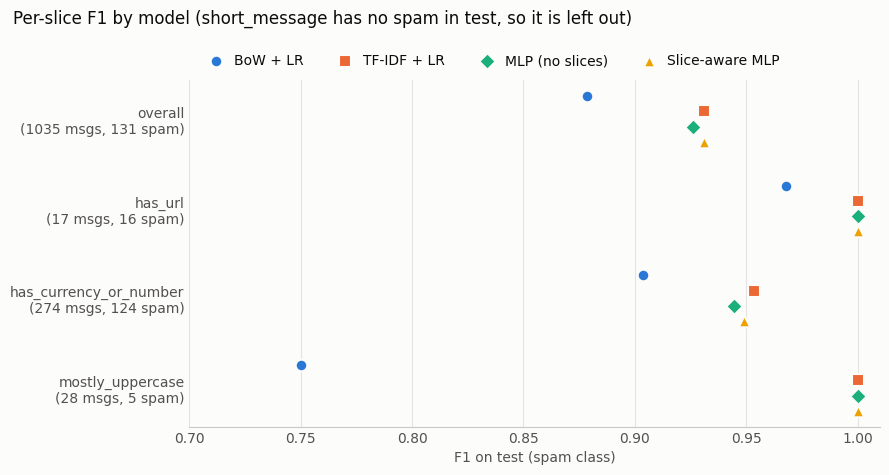

In [15]:
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

INK = "#0b0b0b"
MUTED = "#52514e"
SURFACE = "#fcfcfb"
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

MARKERS = ["o", "s", "D", "^"]

rows = ["overall", "has_url", "has_currency_or_number", "mostly_uppercase"]
row_labels = [
    f"{r}\n({len(df_test) if r == 'overall' else slice_sizes.loc[r, 'test messages']} msgs, "
    f"{int(Y_test.sum()) if r == 'overall' else slice_sizes.loc[r, 'test spam']} spam)"
    for r in rows
]

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for k, (name, color, marker) in enumerate(zip(f1_table.columns, MODEL_COLORS, MARKERS)):
    y = np.arange(len(rows)) + (k - 1.5) * 0.17
    ax.scatter(
        f1_table.loc[rows, name], y, s=70, color=color, marker=marker, label=name,
        edgecolors=SURFACE, linewidths=1.5, zorder=3,
    )
ax.set_yticks(np.arange(len(rows)), row_labels, color=INK)
ax.invert_yaxis()
ax.set_xlim(0.7, 1.01)
ax.set_xlabel("F1 on test (spam class)", color=MUTED)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c8c2")
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK, handletextpad=0.3)
fig.suptitle("Per-slice F1 by model (short_message has no spam in test, so it is left out)", x=0.02, ha="left", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig("results/slice_f1.png", dpi=150, facecolor=SURFACE)
plt.show()

Reading across the four models:
- The slice-aware MLP and the TF-IDF model tie for the best overall F1 (0.931).
- Compared with the same MLP without slice heads, the slice-aware version is only slightly better: overall 0.926 to 0.931, and `has_currency_or_number` 0.945 to 0.949. Most of the jump over the bag-of-words baseline comes from the MLP itself, not from the slice heads.
- `has_currency_or_number` is the lowest scoring slice for the three stronger models.
- The test slices are small (17 messages with links, 28 mostly uppercase), so a single message moves their scores a lot. Like the original says, slice scores on a dataset this size are noisy. Here the SFs are most useful as a monitoring tool that shows where to look.

In [16]:
from utils import save_metrics


def clean(value):
    return None if pd.isna(value) else round(float(value), 4)


metrics = save_metrics(
    "slicing",
    {
        "slices": {
            name: {
                "test_messages": int(row["test messages"]),
                "test_spam": int(row["test spam"]),
                "train_messages": int(row["train messages"]),
            }
            for name, row in slice_sizes.iterrows()
        },
        "bow_vocab_size": hidden_dim,
        "trainer": {"n_epochs": 5, "lr": 1e-3, "batch_size": BATCH_SIZE},
        "f1": {name: {s: clean(v) for s, v in f1_table[name].items()} for name in f1_table.columns},
        "accuracy": {name: {s: clean(v) for s, v in acc_table[name].items()} for name in acc_table.columns},
        "original_c_0.001_overall_f1": clean(slice_scores(original_lr.predict(X_test)).loc["overall", "f1"]),
    },
)
print(list(metrics))

['dataset', 'labeling', 'augmentation', 'slicing']


## Summary

- Four SMS slices: short messages, links, currency or numbers, and mostly uppercase text.
- `Scorer.score_slices` showed that the original's `C=0.001` collapses to all-ham here, and that the bag-of-words baseline is weakest on mostly uppercase messages and on messages with numbers.
- The original's slice-aware approach runs fine on Snorkel 0.9.9. It slightly improves on a plain MLP with the same architecture, and both beat the bag-of-words baseline on every slice that has spam in it.
- The TF-IDF model from part 1 matches the slice-aware MLP without any slice information, a good reminder to always compare against a strong simple baseline.